## 0. Setup Awal

In [1]:
import os
import time
import tracemalloc
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)

plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = 'outputNBAntiBurnoutBernoulli'
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

## 1. Data Understanding

### 1.1 Load Dataset

In [2]:
df = pd.read_csv('burnout_dataset1.csv')

print(f'Jumlah data awal: {len(df)}')

# df = df.sample(
#     n=5000,
#     random_state=42
# ).reset_index(drop=True)
# print(f'Jumlah data setelah sampling: {len(df)}')

Jumlah data awal: 50000


### 1.2 Identifikasi Kolom yang Digunakan

In [3]:
numeric_columns = df.select_dtypes(
    include='number'
).columns

categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

print('Kolom Numerik:')
print(
    numeric_columns.tolist()
)

print(
    '\nKolom Kategorikal:'
)
print(
    categorical_columns.tolist()
)

Kolom Numerik:
['Person_ID', 'Age', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score']

Kolom Kategorikal:
['Gender', 'Country', 'Occupation', 'Education_Level', 'Employment_Status', 'Remote_Work', 'Sleep_Quality', 'Stress_Level', 'Exercise_Frequency', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet', 'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance', 'Support_System', 'Mental_Health_Status', 'AI_Wellness_Recommendation', 'Burnout_Risk']


## 2. Preprocessing

### 2.1 Seleksi Kolom

In [4]:
y = df['Burnout_Risk'].copy()

numeric_columns = numeric_columns.drop(
    ['Person_ID', 'Burnout_Score'],
    errors='ignore'
)

categorical_columns = categorical_columns.drop(
    [
        'Gender',
        'Country',
        'Occupation',
        'AI_Wellness_Recommendation',
        'Burnout_Risk',
        'Education_Level',
        'Employment_Status',
        'Mental_Health_Status'
    ],
    errors='ignore'
)

selected_columns = (
    list(numeric_columns)
    + list(categorical_columns)
)

X = df[
    selected_columns
].copy()

X.head()

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
0,58.0,2786.0,67,3.0,7.0,4.6,74.0,75.0,26.0,18,...,Poor,High,Weekly,Yes,Yes,No,Yes,No,Yes,Average
1,24.0,8027.0,44,5.0,8.0,4.7,58.0,80.0,29.0,37,...,Poor,Moderate,Weekly,Yes,Yes,Yes,No,Yes,No,Good
2,59.0,3177.0,60,8.0,7.0,6.3,54.0,55.0,44.0,48,...,Average,Moderate,Daily,Yes,No,No,No,Yes,No,Average
3,65.0,4093.0,25,2.0,9.0,7.1,12.0,11.0,88.0,80,...,Good,Low,Weekly,Yes,No,No,No,No,Yes,Good
4,64.0,NaN,52,1.0,4.0,9.1,25.0,48.0,67.0,76,...,Excellent,Low,Never,Yes,No,No,No,Yes,No,Poor


### 2.2 Encoding Data Kategorikal

In [5]:
encoding_maps = {
    'Remote_Work': {
        'No': 0,
        'Hybrid': 1,
        'Yes': 2
    },

    'Sleep_Quality': {
        'Excellent': 0,
        'Good': 1,
        'Average': 2,
        'Poor': 3
    },

    'Stress_Level': {
        'Low': 0,
        'Moderate': 1,
        'High': 2
    },

    'Exercise_Frequency': {
        'Daily': 0,
        'Weekly': 1,
        'Rarely': 2,
        'Never': 3
    },

    'Alcohol_Consumption': {
        'No': 0,
        'Yes': 1
    },

    'Smoking': {
        'No': 0,
        'Yes': 1
    },

    'Healthy_Diet': {
        'No': 1,
        'Yes': 0
    },

    'Chronic_Stress': {
        'No': 0,
        'Yes': 1
    },

    'Family_History_Mental_Illness': {
        'No': 0,
        'Yes': 1
    },

    'Therapy_Attendance': {
        'No': 1,
        'Yes': 0
    },

    'Support_System': {
        'Poor': 3,
        'Average': 2,
        'Good': 1,
        'Excellent': 0
    },

    # 'Mental_Health_Status': {
    #     'Healthy': 0,
    #     'Needs Attention': 1,
    #     'Critical': 2
    # }
}

for column, mapping in encoding_maps.items():

    X[column] = (
        X[column]
        .map(mapping)
    )

target_mapping = {
    'Low': 0,
    'Moderate': 1,
    'High': 2
}

y = y.map(target_mapping)

X[categorical_columns].head()

,Remote_Work,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
0,1,3,2,1,1,1,1,1,0,0.0,2
1,1,3,1,1,1,1,0,0,1,1.0,1
2,0,2,1,0,1,0,1,0,1,1.0,2
3,2,1,0,1,1,0,1,0,0,0.0,1
4,0,0,0,3,1,0,1,0,1,1.0,3


### 2.3 Penanganan Missing Values

In [6]:
print(
    'Missing value sebelum train-test split & preprocessing:'
)
print(
    X.isnull().sum()
)
print('\nCatatan: Imputasi mean akan di-fit hanya pada X_train setelah split untuk mencegah data leakage.')

Missing value sebelum train-test split & preprocessing:
Age                               250
Monthly_Income_USD               1450
Work_Hours_Per_Week                 0
Job_Satisfaction                  500
Work_Life_Balance                 650
Sleep_Hours                       950
Anxiety_Score                     800
Depression_Score                  850
Mood_Score                        900
Emotional_Stability                 0
Physical_Activity_Hours          1100
Meditation_Minutes               1200
Screen_Time_Hours                 850
Social_Media_Hours                600
Gaming_Hours                      750
Coffee_Cups_Per_Day                 0
Life_Satisfaction                 700
Productivity_Score                950
Absenteeism_Days                    0
Remote_Work                         0
Sleep_Quality                       0
Stress_Level                        0
Exercise_Frequency                  0
Alcohol_Consumption                 0
Smoking                         

### 2.4 Penanganan Outlier

### 2.5 Standardisasi

In [7]:
# 1. Split data mentah terlebih dahulu agar statistik X_test tidak bocor ke X_train
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 2. Imputasi missing value dan scaling hanya di-fit pada data latih (X_train)
imputer = SimpleImputer(strategy='mean')
X_train_imputed = imputer.fit_transform(X_train_raw)
X_test_imputed = imputer.transform(X_test_raw)

scaler = StandardScaler()
X_train = pd.DataFrame(
    scaler.fit_transform(X_train_imputed),
    columns=X.columns,
    index=X_train_raw.index
)
X_test = pd.DataFrame(
    scaler.transform(X_test_imputed),
    columns=X.columns,
    index=X_test_raw.index
)

X_train.head()

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
18794,1.555718,1.169947,-1.214848,-1.576378,-1.579896e+00,-1.396609,-1.567375,-1.172177,1.580243,1.556101,...,1.593926,-1.012223,-1.349580,1.009142,1.002603,-1.004360,-0.393236,1.006974,-1.011543,-1.345729
18922,0.327757,-0.352506,-1.622237,-0.172846,-8.780165e-01,-1.046550,-0.636677,-1.556041,1.188571,0.405605,...,0.546823,-1.012223,-0.453935,1.009142,-0.997403,0.995659,-0.393236,1.006974,0.996662,0.445174
13028,-0.683504,-0.793965,0.278912,-0.172846,8.766831e-01,-0.871521,-0.675456,0.209736,0.091889,0.405605,...,0.546823,-1.012223,1.337355,-0.990941,-0.997403,0.995659,-0.393236,-0.993074,-1.011543,-1.345729
17779,1.266786,0.872069,1.568978,1.230686,1.227623e+00,-0.813178,1.379836,0.631987,-0.887291,-1.128391,...,0.546823,0.415504,0.441710,-0.990941,-0.997403,-1.004360,-0.393236,-0.993074,-1.011543,0.445174
8978,0.977854,0.231923,1.297385,1.230686,-3.116973e-16,-0.813178,1.573731,1.860354,-2.179808,-1.741989,...,0.546823,1.843232,0.441710,1.009142,1.002603,-1.004360,2.543003,1.006974,-1.011543,-0.450278


### 2.6 Data Bersih

In [8]:
print('Dimensi data fitur mentah (X):', X.shape)
print('Dimensi data latih terstandarisasi (X_train):', X_train.shape)
print('Dimensi data uji terstandarisasi (X_test):', X_test.shape)
print('Jumlah missing value pada X_train:', X_train.isnull().sum().sum())
print('Jumlah missing value pada X_test:', X_test.isnull().sum().sum())
X_train.head()

Dimensi data fitur mentah (X): (50000, 30)
Dimensi data latih terstandarisasi (X_train): (40000, 30)
Dimensi data uji terstandarisasi (X_test): (10000, 30)
Jumlah missing value pada X_train: 0
Jumlah missing value pada X_test: 0


,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
18794,1.555718,1.169947,-1.214848,-1.576378,-1.579896e+00,-1.396609,-1.567375,-1.172177,1.580243,1.556101,...,1.593926,-1.012223,-1.349580,1.009142,1.002603,-1.004360,-0.393236,1.006974,-1.011543,-1.345729
18922,0.327757,-0.352506,-1.622237,-0.172846,-8.780165e-01,-1.046550,-0.636677,-1.556041,1.188571,0.405605,...,0.546823,-1.012223,-0.453935,1.009142,-0.997403,0.995659,-0.393236,1.006974,0.996662,0.445174
13028,-0.683504,-0.793965,0.278912,-0.172846,8.766831e-01,-0.871521,-0.675456,0.209736,0.091889,0.405605,...,0.546823,-1.012223,1.337355,-0.990941,-0.997403,0.995659,-0.393236,-0.993074,-1.011543,-1.345729
17779,1.266786,0.872069,1.568978,1.230686,1.227623e+00,-0.813178,1.379836,0.631987,-0.887291,-1.128391,...,0.546823,0.415504,0.441710,-0.990941,-0.997403,-1.004360,-0.393236,-0.993074,-1.011543,0.445174
8978,0.977854,0.231923,1.297385,1.230686,-3.116973e-16,-0.813178,1.573731,1.860354,-2.179808,-1.741989,...,0.546823,1.843232,0.441710,1.009142,1.002603,-1.004360,2.543003,1.006974,-1.011543,-0.450278


## 3. Modeling

### 3.1 Inisialisasi Model Naive Bayes Bernoulli

In [9]:
model = BernoulliNB(
    alpha=1.0,
    binarize=0.0
)

### 3.2 Eksekusi Model dan Pengukuran Komputasi

In [10]:
tracemalloc.start()
start_time = time.process_time()

model.fit(
    X_train,
    y_train
)

train_time = time.process_time() - start_time
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

train_memory_mb = peak / (1024 * 1024)

print(f'Waktu Eksekusi Training: {train_time:.4f} detik')
print(f'Penggunaan Memori Peak: {train_memory_mb:.4f} MB')

Waktu Eksekusi Training: 0.0469 detik
Penggunaan Memori Peak: 11.6339 MB


### 3.3 Prediksi Data Uji

In [11]:
y_pred = model.predict(
    X_test
)

df_prediksi = pd.DataFrame(
    {
        'Actual': y_test,
        'Predicted': y_pred
    },
    index=X_test.index
)

df_prediksi.head()

,Actual,Predicted
15522,2,2
35306,0,0
90,1,1
48756,0,0
19181,0,0


## 4. Evaluasi

### 4.1 Laporan Klasifikasi (Classification Report)

In [12]:
target_names = ['Low (0)', 'Moderate (1)', 'High (2)']

report = classification_report(
    y_test,
    y_pred,
    target_names=target_names,
    digits=4
)

print(report)

              precision    recall  f1-score   support

     Low (0)     0.9165    0.8565    0.8855      5074
Moderate (1)     0.6336    0.6194    0.6264      2956
    High (2)     0.6744    0.8107    0.7363      1970

    accuracy                         0.7774     10000
   macro avg     0.7415    0.7622    0.7494     10000
weighted avg     0.7852    0.7774    0.7795     10000



### 4.2 Matriks Kebingungan (Confusion Matrix)

In [13]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[4346  686   42]
 [ 396 1831  729]
 [   0  373 1597]]


### 4.3 Metrik Evaluasi Data Uji

In [14]:
acc = accuracy_score(
    y_test,
    y_pred
)

prec_macro = precision_score(
    y_test,
    y_pred,
    average='macro'
)

rec_macro = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1_macro = f1_score(
    y_test,
    y_pred,
    average='macro'
)

f1_weighted = f1_score(
    y_test,
    y_pred,
    average='weighted'
)

print(f'Accuracy           : {acc:.4f}')
print(f'Precision (Macro)  : {prec_macro:.4f}')
print(f'Recall (Macro)     : {rec_macro:.4f}')
print(f'F1-Score (Macro)   : {f1_macro:.4f}')
print(f'F1-Score (Weighted): {f1_weighted:.4f}')

Accuracy           : 0.7774
Precision (Macro)  : 0.7415
Recall (Macro)     : 0.7622
F1-Score (Macro)   : 0.7494
F1-Score (Weighted): 0.7795


### 4.4 Evaluasi Stratified 5-Fold Cross-Validation

In [15]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scoring = {
    'accuracy': 'accuracy',
    'precision_macro': 'precision_macro',
    'recall_macro': 'recall_macro',
    'f1_macro': 'f1_macro',
    'f1_weighted': 'f1_weighted'
}

# Menggunakan Pipeline agar imputasi & scaling di-fit ulang per fold (bebas data leakage)
cv_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler()),
    ('model', BernoulliNB(alpha=1.0, binarize=0.0))
])

cv_results = cross_validate(
    cv_pipeline,
    X,
    y,
    cv=cv,
    scoring=cv_scoring
)

df_cv = pd.DataFrame(
    {
        'Fold': [f'Fold {i+1}' for i in range(5)],
        'Accuracy': cv_results['test_accuracy'],
        'Precision (Macro)': cv_results['test_precision_macro'],
        'Recall (Macro)': cv_results['test_recall_macro'],
        'F1-Score (Macro)': cv_results['test_f1_macro'],
        'F1-Score (Weighted)': cv_results['test_f1_weighted']
    }
)

df_cv.loc['Mean'] = df_cv.mean(numeric_only=True)
df_cv.loc['Std'] = df_cv.std(numeric_only=True)
df_cv

,Fold,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Weighted)
0,Fold 1,0.771300,0.733433,0.753154,0.740915,0.772616
1,Fold 2,0.785000,0.751117,0.768408,0.758212,0.786190
2,Fold 3,0.776600,0.740507,0.758193,0.747585,0.778138
3,Fold 4,0.773900,0.737231,0.756965,0.744847,0.775848
4,Fold 5,0.773700,0.736843,0.755976,0.744253,0.774822
Mean,NaN,0.776100,0.739826,0.758539,0.747163,0.777523
Std,NaN,0.004756,0.006074,0.005207,0.005918,0.004683


### 4.5 Ringkasan Waktu Eksekusi dan Penggunaan Memori

In [16]:
df_runtime = pd.DataFrame(
    [
        {
            'Model': 'Naive Bayes (BernoulliNB)',
            'Training_Time_Seconds': round(train_time, 4),
            'Peak_Memory_MB': round(train_memory_mb, 4)
        }
    ]
)

df_runtime

,Model,Training_Time_Seconds,Peak_Memory_MB
0,Naive Bayes (BernoulliNB),0.0469,11.6339


### 4.6 Ringkasan Evaluasi Model

In [17]:
evaluation_result = pd.DataFrame(
    {
        'Model': ['Naive Bayes (BernoulliNB)'],
        'Distribusi': ['Bernoulli'],
        'Alpha': [1.0],
        'Binarize': [0.0],
        'Accuracy': [round(acc, 4)],
        'Precision_Macro': [round(prec_macro, 4)],
        'Recall_Macro': [round(rec_macro, 4)],
        'F1_Score_Macro': [round(f1_macro, 4)],
        'F1_Score_Weighted': [round(f1_weighted, 4)],
        'CV_5Fold_Accuracy_Mean': [round(cv_results['test_accuracy'].mean(), 4)],
        'CV_5Fold_F1_Macro_Mean': [round(cv_results['test_f1_macro'].mean(), 4)],
        'Training_Time_s': [round(train_time, 4)],
        'Peak_Memory_MB': [round(train_memory_mb, 4)]
    }
)

evaluation_result

,Model,Distribusi,Alpha,Binarize,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Peak_Memory_MB
0,Naive Bayes (BernoulliNB),Bernoulli,1.0,0.0,0.7774,0.7415,0.7622,0.7494,0.7795,0.7761,0.7472,0.0469,11.6339


## 5. Visualisasi Hasil

### 5.1 Visualisasi Confusion Matrix Heatmap

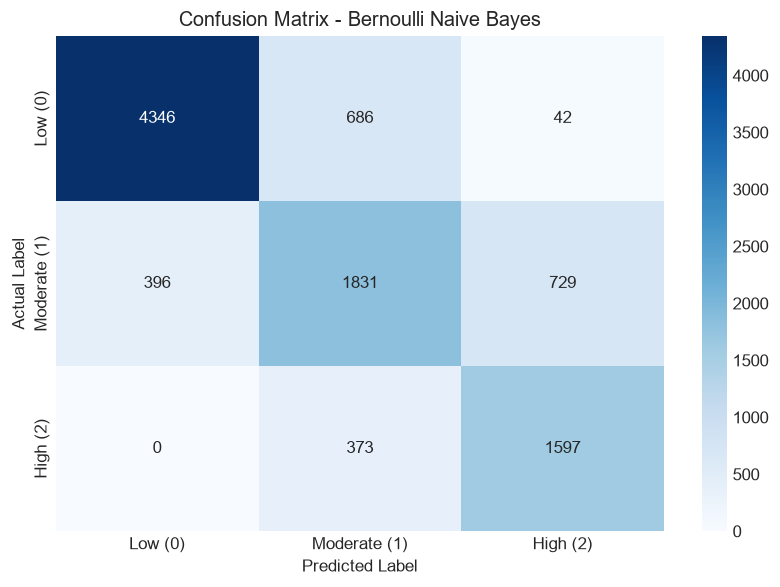

In [18]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names
)
plt.title('Confusion Matrix - Bernoulli Naive Bayes')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/confusion_matrix_bernoulli.png'
)
plt.show()

### 5.2 Visualisasi Distribusi Kelas Prediksi vs Aktual

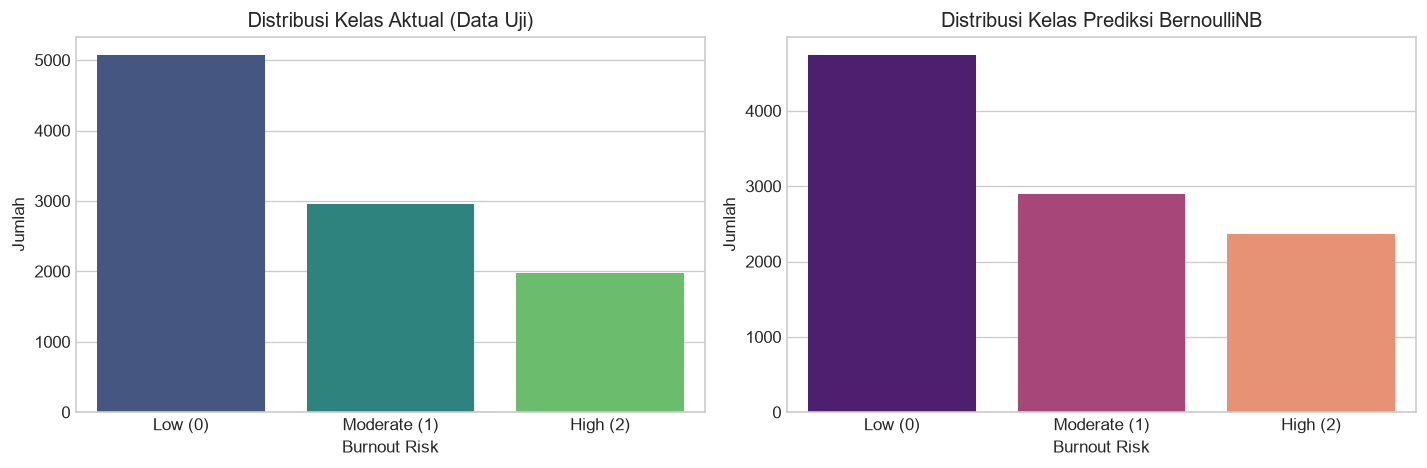

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    x=y_test,
    ax=axes[0],
    palette='viridis'
)
axes[0].set_title('Distribusi Kelas Aktual (Data Uji)')
axes[0].set_xticklabels(target_names)
axes[0].set_xlabel('Burnout Risk')
axes[0].set_ylabel('Jumlah')

sns.countplot(
    x=y_pred,
    ax=axes[1],
    palette='magma'
)
axes[1].set_title('Distribusi Kelas Prediksi BernoulliNB')
axes[1].set_xticklabels(target_names)
axes[1].set_xlabel('Burnout Risk')
axes[1].set_ylabel('Jumlah')

plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/distribution_actual_vs_predicted_bernoulli.png'
)
plt.show()

### 5.3 Visualisasi Metrik Evaluasi Stratified 5-Fold Cross-Validation

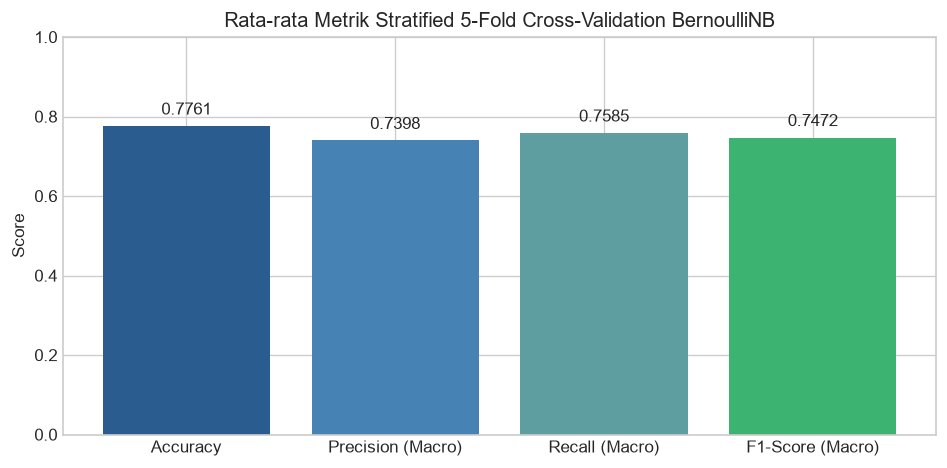

In [20]:
metrics_cv = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)']
cv_means = [
    cv_results['test_accuracy'].mean(),
    cv_results['test_precision_macro'].mean(),
    cv_results['test_recall_macro'].mean(),
    cv_results['test_f1_macro'].mean()
]

plt.figure(figsize=(8, 4))
bars = plt.bar(
    metrics_cv,
    cv_means,
    color=['#2b5c8f', '#4682b4', '#5f9ea0', '#3cb371']
)
plt.title('Rata-rata Metrik Stratified 5-Fold Cross-Validation BernoulliNB')
plt.ylabel('Score')
plt.ylim(0, 1)

for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.02,
        f'{yval:.4f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/cv_metrics_bernoulli.png'
)
plt.show()

## 6. Analisis

### 6.1 Analisis Prior Probabilitas dan Log Probabilitas Fitur (Feature Log Prob)

In [21]:
df_priors = pd.DataFrame(
    {
        'Kelas': target_names,
        'Prior_Probability': [round(p, 4) for p in model.class_log_prior_]
    }
)

df_log_prob = pd.DataFrame(
    model.feature_log_prob_,
    columns=X.columns,
    index=target_names
)

print('Log Prior Probability per Kelas:')
display(df_priors)
print('\nFeature Log Probability per Kelas (10 Fitur Pertama):')
df_log_prob.T.head(10)

Log Prior Probability per Kelas:


,Kelas,Prior_Probability
0,Low (0),-0.6785
1,Moderate (1),-1.2187
2,High (2),-1.6244



Feature Log Probability per Kelas (10 Fitur Pertama):


,Low (0),Moderate (1),High (2)
Age,-0.703796,-0.698234,-0.704758
Monthly_Income_USD,-0.725645,-0.734759,-0.729444
Work_Hours_Per_Week,-1.271763,-0.436772,-0.123237
Job_Satisfaction,-0.679884,-0.700446,-0.681669
Work_Life_Balance,-0.703398,-0.711236,-0.693020
Sleep_Hours,-0.518674,-0.733525,-0.982226
Anxiety_Score,-2.230231,-0.264447,-0.015726
Depression_Score,-2.143793,-0.283575,-0.017016
Mood_Score,-0.138322,-1.512100,-7.180704
Emotional_Stability,-0.131668,-1.471509,-6.407514


### 6.2 Visualisasi 10 Fitur dengan Variasi Probabilitas Tertinggi Antar-Kelas

<Figure size 1440x720 with 0 Axes>

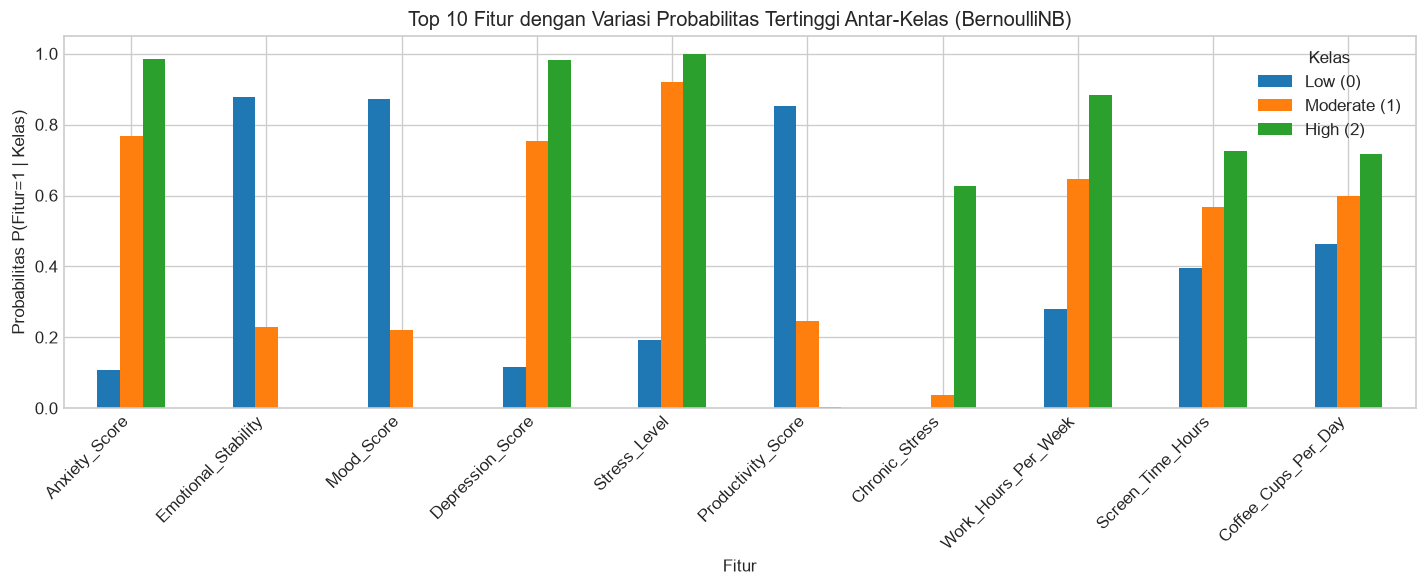

In [22]:
df_prob = pd.DataFrame(
    np.exp(model.feature_log_prob_),
    columns=X.columns,
    index=target_names
)

plt.figure(figsize=(12, 6))
top_diff = df_prob.std().sort_values(ascending=False).head(10)
df_prob[top_diff.index].T.plot(kind='bar', figsize=(12, 5))
plt.title('Top 10 Fitur dengan Variasi Probabilitas Tertinggi Antar-Kelas (BernoulliNB)')
plt.ylabel('Probabilitas P(Fitur=1 | Kelas)')
plt.xlabel('Fitur')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Kelas')
plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/top_feature_probabilities_bernoulli.png'
)
plt.show()

## 7. Ekspor File

### 7.1 Ekspor Ringkasan Evaluasi

In [23]:
evaluation_result.to_csv(
    f'{OUTPUT_DIR}/metrics_nb_bernoulli.csv',
    index=False
)

### 7.2 Ekspor Hasil Prediksi Data Uji

In [24]:
df_prediksi.to_csv(
    f'{OUTPUT_DIR}/predictions_nb_bernoulli.csv'
)

### 7.3 Ekspor Hasil 5-Fold Cross-Validation

In [25]:
df_cv.to_csv(
    f'{OUTPUT_DIR}/cv_5fold_nb_bernoulli.csv'
)